<a href="https://colab.research.google.com/github/kvikaee/machine-learning/blob/main/ML_6_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Нейронные сети

В этой работе пригодится библиотека PyTorch из лабораторной работы №1.

По нейронным сетям в интернете можно найти огромное количество информации и примеров (официальная документация фреймворка, Kaggle, даже ChatGPT, хотя последний стоит использовать с осторожностью) - вы можете использовать любые материалы в текущей работе, но будьте готовы ответить на вопросы по коду во время защиты.

Вспомогательные материалы:

[Курс по нейронным сетям](https://stepik.org/course/110281/syllabus)

[ШАД-овский курс по глубокому обучению](https://github.com/yandexdataschool/Practical_DL/tree/fall23)


В целом, содержательно данная работа дублирует часть курса по Глубокому обучению.


## Основы нейронных сетей (4 балла)

Кратко обсудим основные концепции, понимание которых необходимо для работы с PyTorch. В других фреймворках для нейронных сетей всё очень похоже.

1. **Датасеты**
  
  В PyTorch датасеты представлены классами `torch.utils.data.Dataset` или его наследниками. Они позволяют загружать данные и предоставляют доступ к ним для обучения и валидации.

2. **Нейронные сети**

  *Слои*

  Нейронные сети в PyTorch строятся с использованием `torch.nn.Module` (не единственный, но самый распространенный способ). Слои определяются внутри этих модулей и могут быть полносвязными (`torch.nn.Linear`), сверточными (`torch.nn.Conv2d`), рекуррентными (`torch.nn.LSTM`, `torch.nn.GRU`) и другими. Сло имеют входную и выходную размерность. В нейронной сети выходная размерность слоя должна быть равна входной размерности последующего слоя.

  *Функции активации*

  Функции активации, такие как ReLU (`torch.nn.ReLU`), Sigmoid (`torch.nn.Sigmoid`), Tanh (`torch.nn.Tanh`) и другие, применяются к выходу слоя для добавления нелинейности в сеть.

  *Лосс-функции*

  Лосс-функции измеряют расхождение между прогнозами модели и фактическими значениями. В зависимости от типа задачи могут использоваться различные функции активации, например, `torch.nn.CrossEntropyLoss` для классификации и `torch.nn.MSELoss` для регрессии.

  *Оптимизаторы*

  Оптимизаторы в PyTorch, такие как `torch.optim.SGD`, `torch.optim.Adam`, `torch.optim.Adagrad` и другие, используются для обновления параметров сети в процессе обучения с целью минимизации функции потерь.

  *Планировщики (шедулеры)*

  Планировщики позволяют динамически изменять скорость обучения в процессе обучения. Например, `torch.optim.lr_scheduler.ReduceLROnPlateau` уменьшает скорость обучения, если ошибка перестает уменьшаться, а `torch.optim.lr_scheduler.StepLR` или `torch.optim.lr_scheduler.CosineAnnealingLR` изменяют скорость обучения в заданные моменты или с периодическим расписанием.

3. **Обучение и валидация**

  Обучение модели включает в себя передачу данных через сеть, вычисление функции потерь, вычисление градиентов, обновление весов с использованием оптимизатора и повторение этого процесса на протяжении нескольких эпох. После обучения модели необходимо провести валидацию на независимом наборе данных для оценки ее производительности.

[Визуализация работы нейронных сетей](https://playground.tensorflow.org/).

Потренируемся писать полный цикл обучения нейронной сети на [следующем наборе данных](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data).

P.S. предлагаемая архитектура сети не является оптимальной, но позволяет научиться работать с основными строительными блоками PyTorch-а.

Прочитайте датасет (можно использовать библиотеку `opendatasets` для выгрузки данных с Kaggle). Посчитайте основные числовые характеристики для каждого столбца. Проанализируйте датасет на предмет дисбаланса классов. Сделайте вывод о необходимости каких-либо преобразований над данными.

Разбейте выборку на тренировочную и тестовую (`test_size=0.2, random_state=42`), проведите необходимые преобразования.

### Загурзка и чистка

In [ ]:
!pip install legacy-cgi -q

In [ ]:
import opendatasets as od
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import matplotlib.pyplot as plt

od.download("https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data")
df = pd.read_csv('breast-cancer-wisconsin-data/data.csv')

print("Размер:", df.shape)
print("\nЧисловые характеристики:")
print(df.describe())

# смотрим на баланс классов
print("\nКлассы:")
print(df['diagnosis'].value_counts())
print(df['diagnosis'].value_counts(normalize=True).round(3))

Skipping, found downloaded files in "./breast-cancer-wisconsin-data" (use force=True to force download)
Размер: (569, 33)

Числовые характеристики:
                 id  radius_mean  texture_mean  perimeter_mean    area_mean  \
count  5.690000e+02   569.000000    569.000000      569.000000   569.000000   
mean   3.037183e+07    14.127292     19.289649       91.969033   654.889104   
std    1.250206e+08     3.524049      4.301036       24.298981   351.914129   
min    8.670000e+03     6.981000      9.710000       43.790000   143.500000   
25%    8.692180e+05    11.700000     16.170000       75.170000   420.300000   
50%    9.060240e+05    13.370000     18.840000       86.240000   551.100000   
75%    8.813129e+06    15.780000     21.800000      104.100000   782.700000   
max    9.113205e+08    28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000   

In [ ]:
# таргет в числа: m=1, b=0
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# убираем служебные столбцы: id — номер пациента, unnamed: 32 — артефакт csv
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# нормализация: фитим только на train, применяем к обоим наборам
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

train_df = pd.DataFrame(X_train, columns=X.columns)
train_df['diagnosis'] = y_train.values
test_df = pd.DataFrame(X_test, columns=X.columns)
test_df['diagnosis'] = y_test.values

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
print("train:", train_df.shape, "test:", test_df.shape)

cuda
train: (455, 31) test: (114, 31)


Создайте класс датасета. Типы данных, которые вам потребуются: `dtype=torch.float32`, `dtype=torch.long`.

Инициализируйте даталоадеры (`batch_size=32`) для тренировочных и тестовых данных. Для теста данные перемешивать (параметр `shuffle`) не надо!

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, dataframe):
        self.data = torch.tensor(
            dataframe.drop(columns=['diagnosis']).values, dtype=torch.float32
        )
        self.target = torch.tensor(
            dataframe['diagnosis'].values, dtype=torch.long
        )

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]


train_dataset = CustomDataset(train_df)
test_dataset = CustomDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Создайте полносвязную нейронную сеть из нескольких слоёв. Между слоями используйте ReLU.

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size):
        super(NeuralNetwork, self).__init__()
        # полносвязная сеть: 30 → 64 → 32 → 2
        # между слоями relu для нелинейности
        self.net = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.net(x)

Следующий небольшой кусочек кода написан за вас. В нём используется кросс-энтропия в качестве функции потерь. Вспомните, какими характеристиками обладает данная функция и в чём особенность её реализации в PyTorch.

Письменно ответьте на вопрос, как сигмоидальная функция потерь соотносится с кросс-энтропийной.

In [ ]:
model = NeuralNetwork(input_size=train_df.shape[1] - 1).to(device)  # -1 за счет таргета
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)

num_epochs = 15
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

Сигмоидальная функция и кросс-энтропия тесно связаны: при бинарной классификации сигмоида применяется к выходу модели, чтобы получить вероятность, после чего вычисляется бинарная кросс-энтропия (BCE). Формула BCE фактически является частным случаем общей кросс-энтропии для двух классов.

В PyTorch nn.CrossEntropyLoss объединяет в себе LogSoftmax + NLLLoss и принимает сырые логиты (без предварительного применения softmax или сигмоиды). Это сделано намеренно: совместное вычисление численно устойчивее, чем последовательное применение softmax и затем взятие логарифма.

При двух классах nn.CrossEntropyLoss(logits) даёт результат, эквивалентный nn.BCEWithLogitsLoss(logits[:, 1]), — оба варианта вычисляют одно и то же, просто CrossEntropyLoss работает с векторами логитов для любого числа классов.

Напишите функции для тренировки и тестирования модели. Не забудьте про `optimizer.zero_grad()` при тренировке и `with torch.no_grad()` в тесте.

Также обратите внимание, что шаг планировщика нужно совершать после шага оптимизатора.

In [ ]:
def train(model, train_loader, criterion, optimizer, scheduler, device):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in tqdm(train_loader, leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        # обнуляем градиенты
        optimizer.zero_grad()
        # forward
        outputs = model(inputs)
        # считаем loss
        loss = criterion(outputs, labels)
        # backward
        loss.backward()
        # шаг оптимизатора
        optimizer.step()

        # накапливаем лосс (домножаем на размер батча, чтобы потом усреднить)
        running_loss += loss.item() * inputs.size(0)
        # точность
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    # шаг планировщика — после шага оптимизатора
    scheduler.step()

    train_loss = running_loss / total_train
    train_accuracy = correct_train / total_train
    return train_loss, train_accuracy


def test(model, test_loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for inputs, labels in tqdm(test_loader, leave=False):
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct_test += (preds == labels).sum().item()
            total_test += labels.size(0)

    test_loss = running_loss / total_test
    test_accuracy = correct_test / total_test
    return test_loss, test_accuracy

Epoch  1/15 | train_loss=0.6200 train_acc=0.7495 | test_loss=0.5083 test_acc=0.9211


Epoch  2/15 | train_loss=0.4203 train_acc=0.9341 | test_loss=0.3018 test_acc=0.9474


Epoch  3/15 | train_loss=0.2460 train_acc=0.9473 | test_loss=0.1567 test_acc=0.9737


Epoch  4/15 | train_loss=0.1492 train_acc=0.9538 | test_loss=0.0989 test_acc=0.9737


Epoch  5/15 | train_loss=0.1058 train_acc=0.9692 | test_loss=0.0794 test_acc=0.9737


Epoch  6/15 | train_loss=0.0855 train_acc=0.9758 | test_loss=0.0721 test_acc=0.9737


... (5 outputs left out)

Epoch 12/15 | train_loss=0.0519 train_acc=0.9846 | test_loss=0.0655 test_acc=0.9825


Epoch 13/15 | train_loss=0.0514 train_acc=0.9846 | test_loss=0.0654 test_acc=0.9825


Epoch 14/15 | train_loss=0.0510 train_acc=0.9846 | test_loss=0.0654 test_acc=0.9825


Epoch 15/15 | train_loss=0.0506 train_acc=0.9846 | test_loss=0.0654 test_acc=0.9825


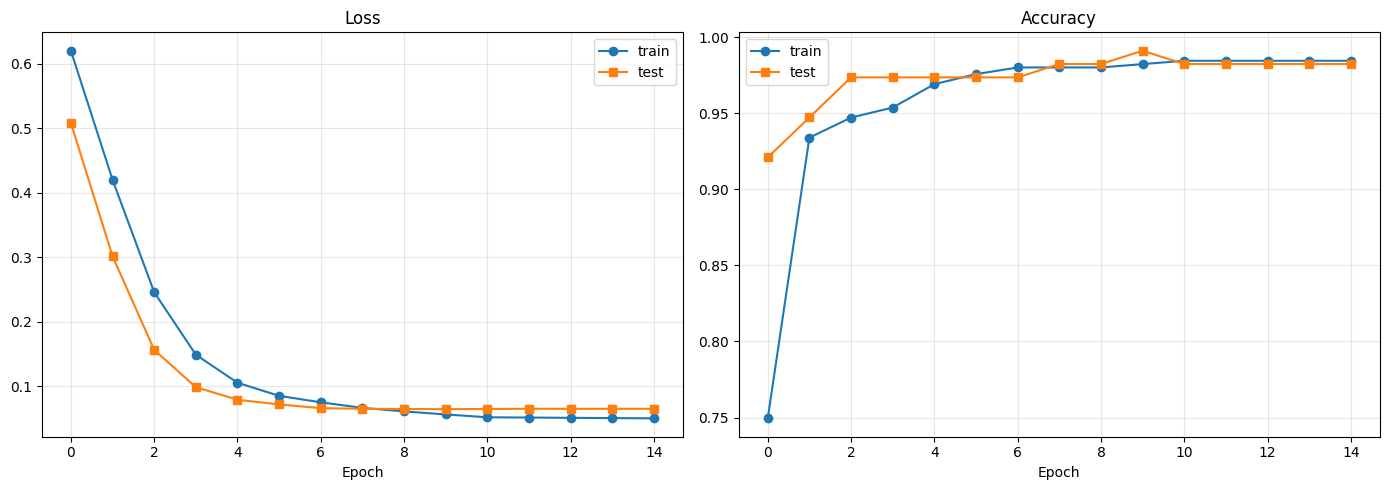

In [ ]:
for epoch in range(num_epochs):
    tr_loss, tr_acc = train(model, train_loader, criterion, optimizer, scheduler, device)
    te_loss, te_acc = test(model, test_loader, criterion, device)

    train_losses.append(tr_loss)
    test_losses.append(te_loss)
    train_accuracies.append(tr_acc)
    test_accuracies.append(te_acc)

    print(f"Epoch {epoch+1:2d}/{num_epochs} | "
          f"train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} | "
          f"test_loss={te_loss:.4f} test_acc={te_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_losses, label='train', marker='o')
axes[0].plot(test_losses, label='test', marker='s')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(train_accuracies, label='train', marker='o')
axes[1].plot(test_accuracies, label='test', marker='s')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Создайте цикл обучения вашей нейронной сети, используя написанные ранее функции.

Печатайте прогресс на каждой эпохе (`train_loss, train_accuracy, test_loss, test_accuracy`).

Постройте графики лосса и точности. Должно получиться что-то такое:

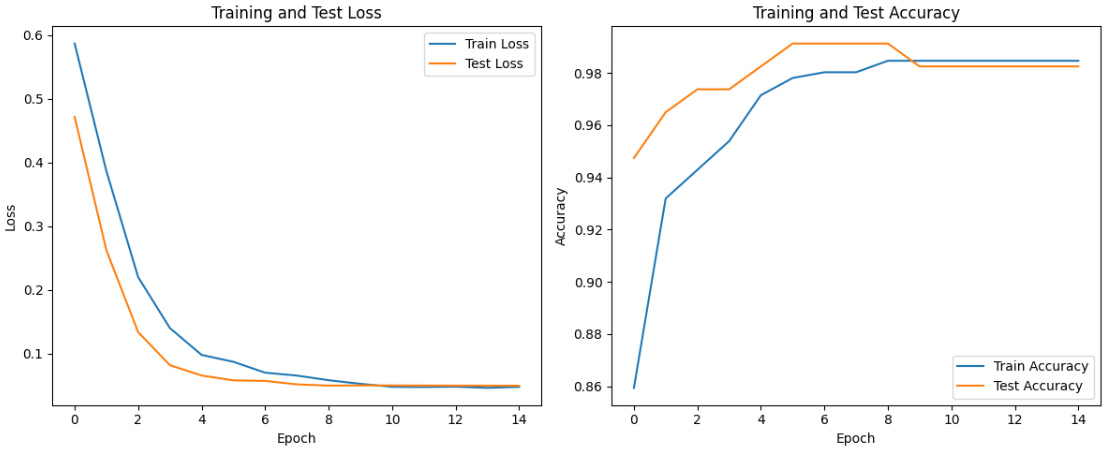

In [ ]:
torch.save(model.state_dict(), 'model_checkpoint.pth')

## Специальные архитектуры нейронных сетей

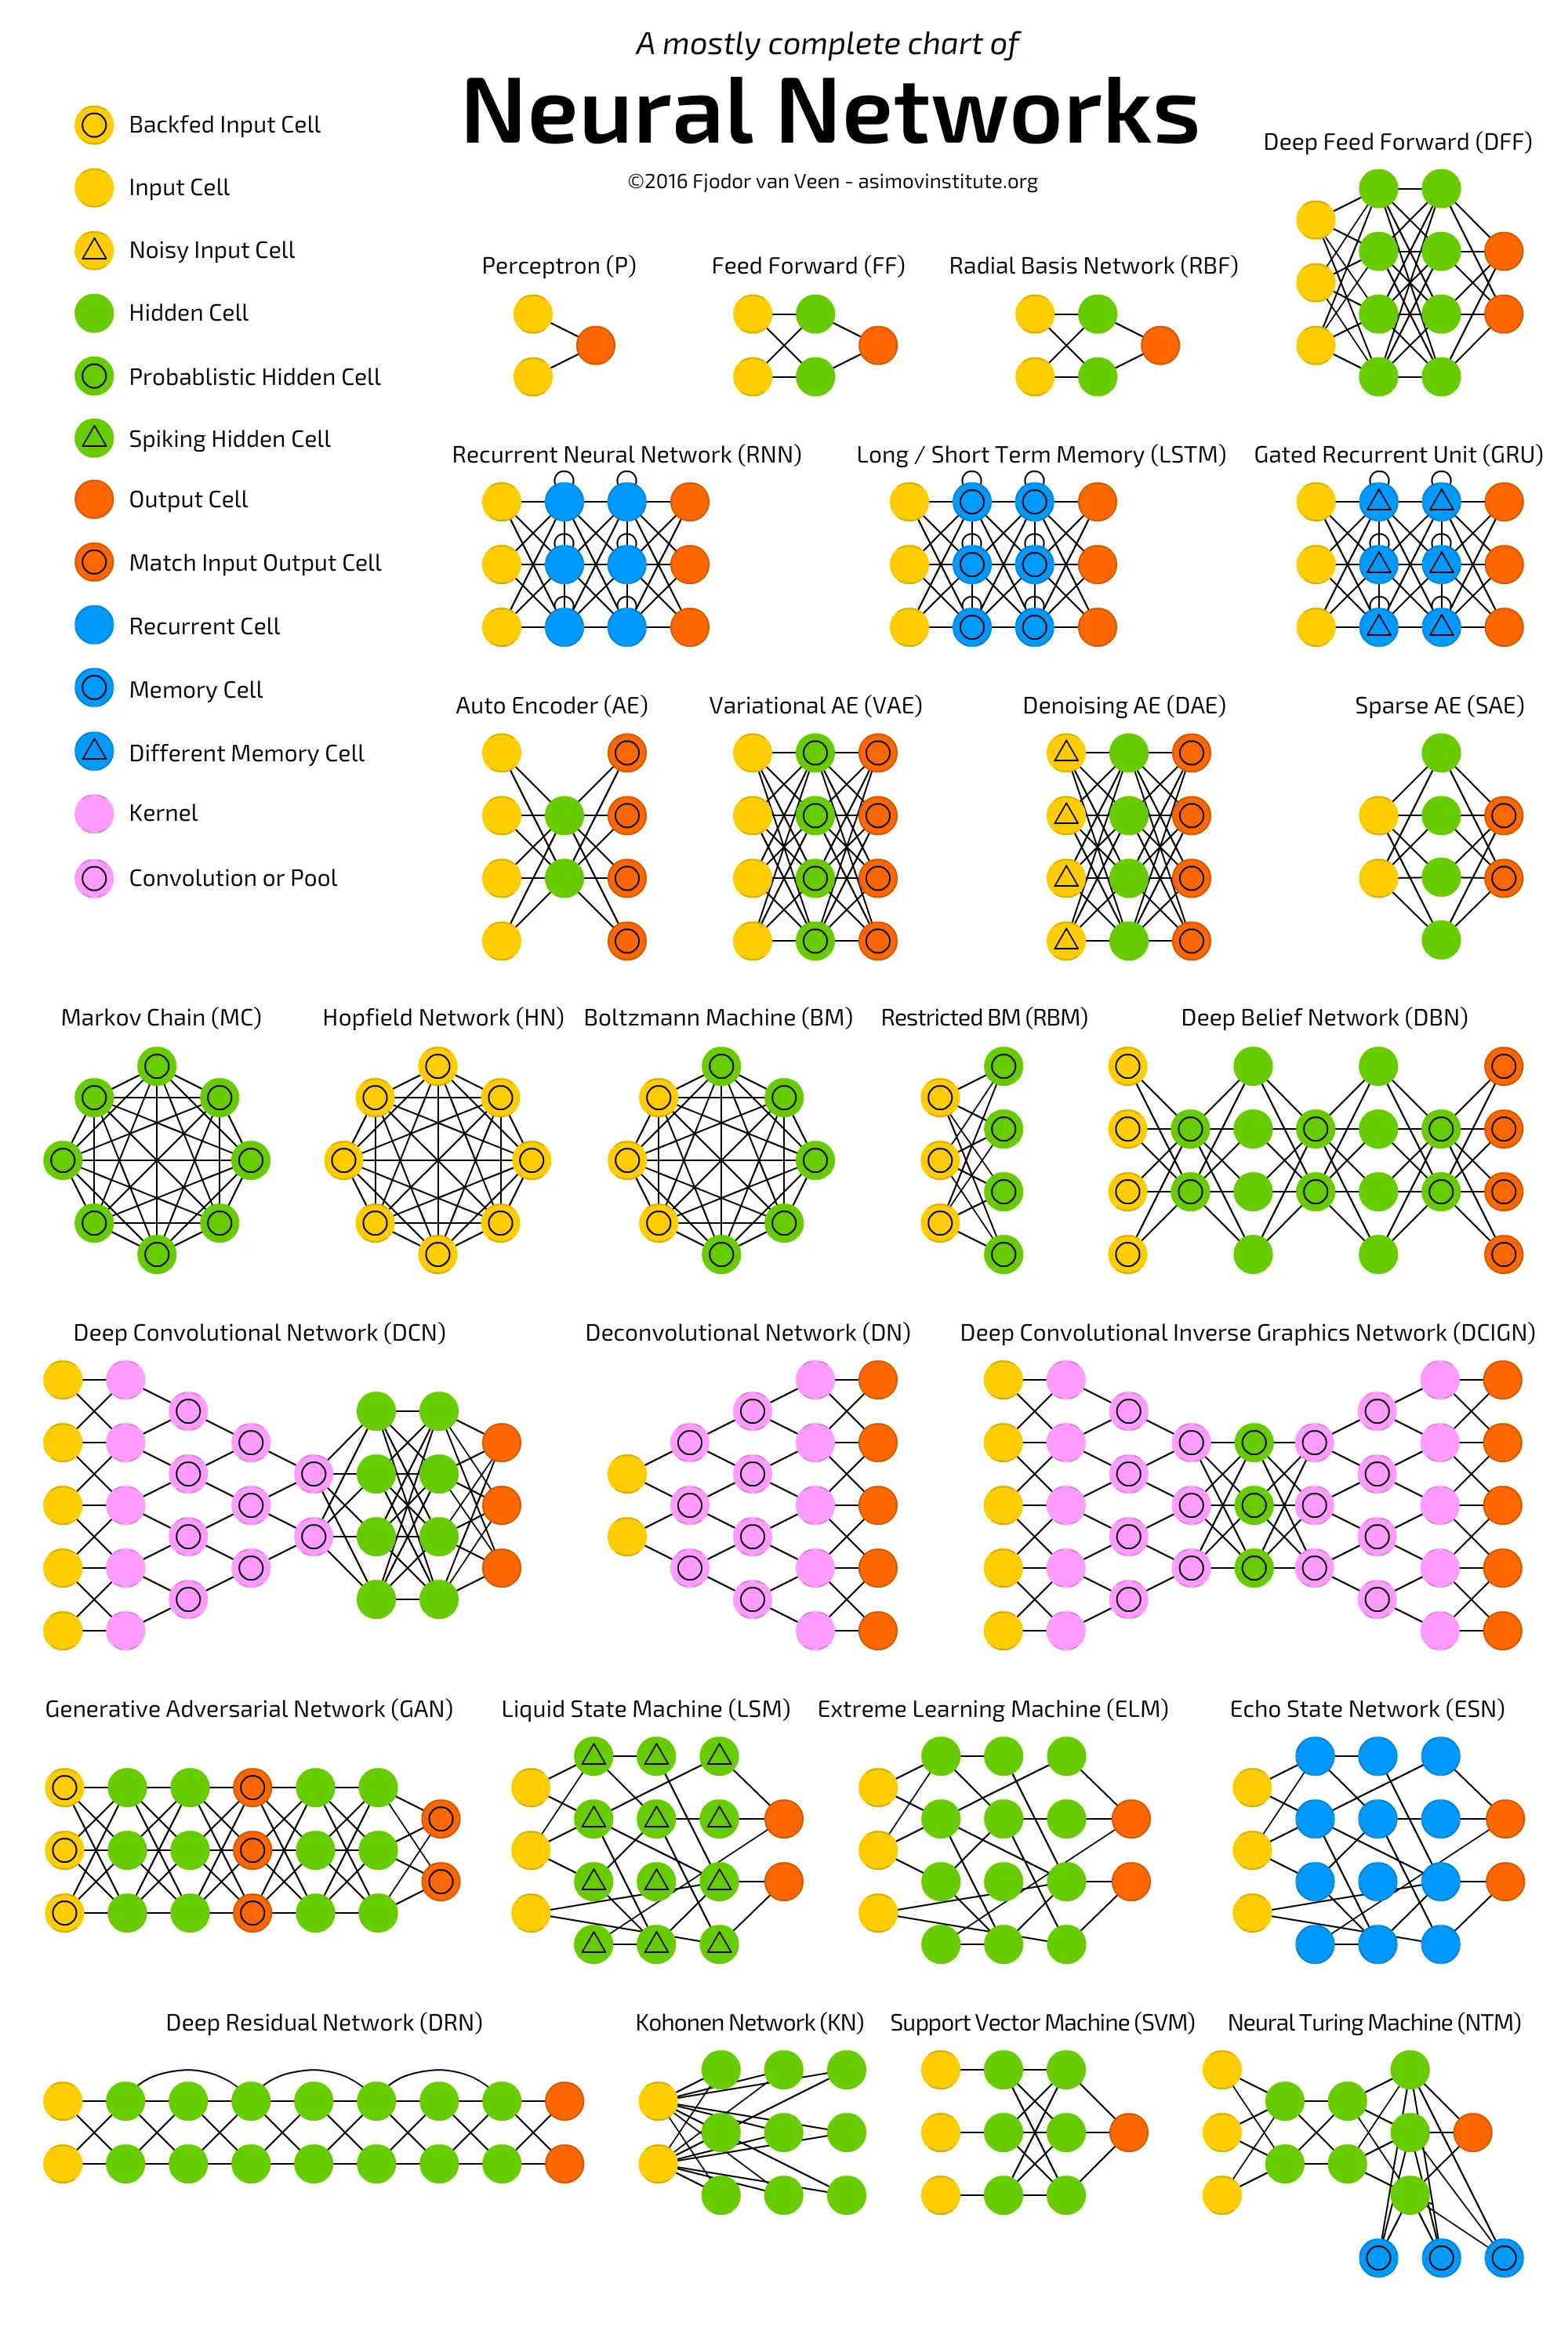

[Источник картинки](https://towardsdatascience.com/the-mostly-complete-chart-of-neural-networks-explained-3fb6f2367464)

В последующих заданиях можно использовать предоставленные датасеты ЛИБО найти какой-либо свой, обладающий схожими характеристиками.

### CNN (4 балла)

Свёрточные нейронные сети работают по принципу "возьмем фильтры с настраиваемыми весами и будем изменять эти веса так, чтобы фильтры выделяли те признаки, которые помогут нам решить задачу". Обычно свёрточные нейронные сети состоят из блоков свёртки и пулинга (уменьшение размерности), поверх которых добавляются несколько полносвязных линейных слоёв. [Визуализация работы свёрточной нейронной сети](https://poloclub.github.io/cnn-explainer/)

Будем решать задачу многоклассовой классификации. Датасет возьмем [отсюда](https://www.kaggle.com/datasets/puneet6060/intel-image-classification/data). Он содержит картинки с различными пейзажами. Присутсвуют такие классы, как 'buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'.

Скачайте датасет (можно использвоать библиотеку `opendatasets`)

In [ ]:
!pip install opendatasets -q

In [ ]:
import os

In [ ]:
import torchvision
from torchvision import datasets
import torchvision.transforms as transforms
import numpy as np
from PIL import Image

In [ ]:
import opendatasets as od
od.download("https://www.kaggle.com/datasets/puneet6060/intel-image-classification", force=True)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: kvikaee
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification


100%|██████████| 346M/346M [00:18<00:00, 20.0MB/s]


Создайте даталоадеры для тренировочных и тестовых данных. Используйте `torchvision.datasets.ImageFolder`. Одним из параметров данной функции является `transform`. Попробуйте применить к вашим данным какие-либо [трансформации](https://pytorch.org/vision/stable/transforms.html).

In [ ]:
train_path = "intel-image-classification/seg_train/seg_train"
test_path = "intel-image-classification/seg_test/seg_test"
batch_size = 256

transformer = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

train_dataset_cnn = datasets.ImageFolder(train_path, transform=transformer)
test_dataset_cnn = datasets.ImageFolder(test_path, transform=transformer)

train_loader = DataLoader(train_dataset_cnn, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset_cnn, batch_size=batch_size, shuffle=False)

Выведем пару картинок, обратившись к содержимому даталоадеров.

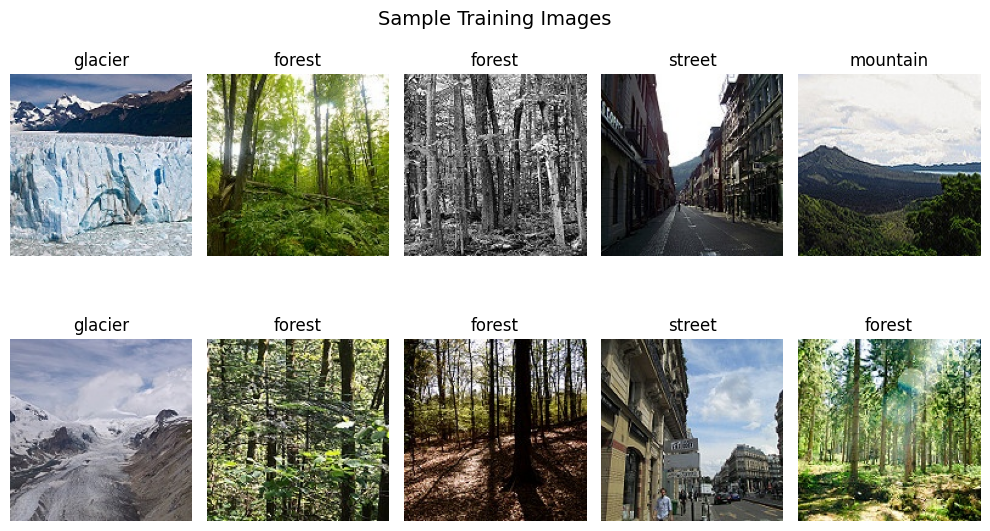

In [ ]:
images, labels = next(iter(train_loader))
class_names = train_loader.dataset.classes

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(10, 6))
idx = 0

for i in range(2):
    for j in range(5):
        label = class_names[labels[idx].item()]
        ax[i, j].set_title(f"{label}")
        img = images[idx]

        img = img / 2 + 0.5  # обратное преобразование из-за трансформаций. возможно, вам оно не пригодится

        npimg = np.transpose(img.numpy(), (1, 2, 0))
        ax[i, j].imshow(npimg)
        ax[i, j].axis("off")
        idx += 1

plt.tight_layout()
plt.suptitle("Sample Training Images", fontsize=14)
plt.show()

Реализуйте свёрточную нейронную сеть и обучите её, используя тот же пайплайн, что и в предыдущем задании.

Задача не из простых, так как при использовании свёрточных нейронных сетей нужно внимательно следить за размерностями входных и выходных слоёв. Вам пригодятся такие слои, как Conv2d, BatchNorm2d, MaxPool2d, Linear или любые другие на ваше усмотрение. В качестве функции активации можно использовать ReLU.

Задача достаточно творческая, сфокусируйтесь на проведении экспериментов, а не на том, чтобы "выбить метрику". В данной задаче accuracy выше 0.7 на тесте будем считать хорошим результатом.

In [ ]:
class ConvNet(nn.Module):
    def __init__(self, num_classes=6):
        super(ConvNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 18 * 18, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, input):
        x = self.features(input)
        x = self.classifier(x)
        return x

In [ ]:
model = ConvNet(num_classes=6).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

total_params = sum(p.numel() for p in model.parameters())
print(f"всего параметров: {total_params:,}")

всего параметров: 10,712,326


In [ ]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

epoch  1/10 | train_loss=2.4801 acc=0.4682 | test_loss=0.9839 acc=0.6183
epoch  2/10 | train_loss=0.9421 acc=0.6347 | test_loss=0.7873 acc=0.7107
epoch  3/10 | train_loss=0.8193 acc=0.6930 | test_loss=0.7352 acc=0.7317
epoch  4/10 | train_loss=0.7269 acc=0.7382 | test_loss=0.6739 acc=0.7547
epoch  5/10 | train_loss=0.6624 acc=0.7585 | test_loss=0.6625 acc=0.7667
epoch  6/10 | train_loss=0.5765 acc=0.7943 | test_loss=0.5196 acc=0.8187
epoch  7/10 | train_loss=0.5479 acc=0.8018 | test_loss=0.5036 acc=0.8273
epoch  8/10 | train_loss=0.5220 acc=0.8107 | test_loss=0.4870 acc=0.8287
epoch  9/10 | train_loss=0.4899 acc=0.8290 | test_loss=0.5068 acc=0.8260
epoch 10/10 | train_loss=0.4670 acc=0.8293 | test_loss=0.4706 acc=0.8353


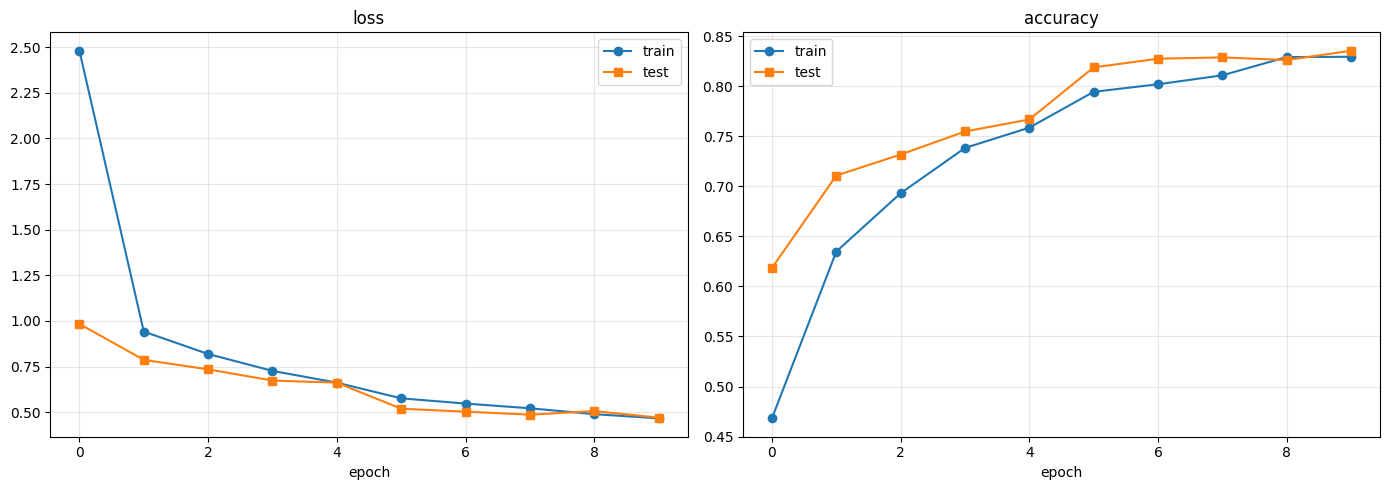

In [ ]:
num_epochs = 10
train_losses, test_losses = [], []
train_accs, test_accs = [], []

for epoch in range(num_epochs):
    tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    te_loss, te_acc, _, _ = evaluate(model, test_loader, criterion, device)
    scheduler.step()
    train_losses.append(tr_loss); test_losses.append(te_loss)
    train_accs.append(tr_acc); test_accs.append(te_acc)
    print(f"epoch {epoch+1:2d}/{num_epochs} | "
          f"train_loss={tr_loss:.4f} acc={tr_acc:.4f} | "
          f"test_loss={te_loss:.4f} acc={te_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_losses, label='train', marker='o')
axes[0].plot(test_losses, label='test', marker='s')
axes[0].set_title('loss'); axes[0].set_xlabel('epoch'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(train_accs, label='train', marker='o')
axes[1].plot(test_accs, label='test', marker='s')
axes[1].set_title('accuracy'); axes[1].set_xlabel('epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


финальная accuracy на тесте: 0.8353

              precision    recall  f1-score   support

   buildings       0.81      0.82      0.82       437
      forest       0.94      0.94      0.94       474
     glacier       0.78      0.82      0.80       553
    mountain       0.78      0.77      0.77       525
         sea       0.85      0.83      0.84       510
      street       0.87      0.84      0.85       501

    accuracy                           0.84      3000
   macro avg       0.84      0.84      0.84      3000
weighted avg       0.84      0.84      0.84      3000



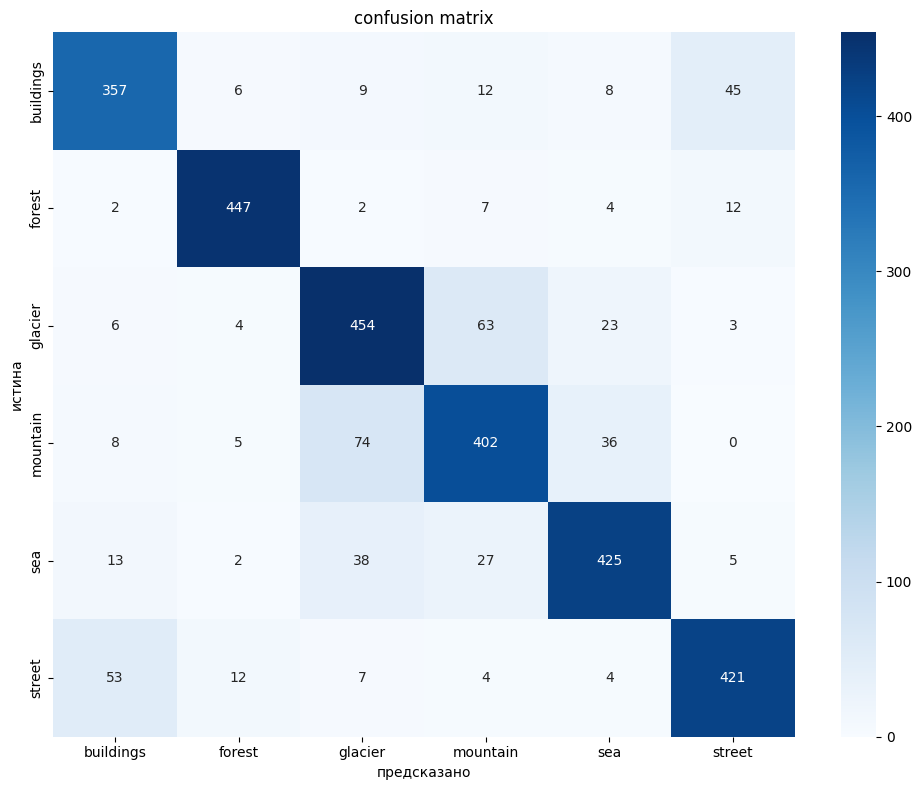

In [ ]:
_, final_acc, preds, labels = evaluate(model, test_loader, criterion, device)
print(f"финальная accuracy на тесте: {final_acc:.4f}")
print()
print(classification_report(labels, preds, target_names=train_dataset_cnn.classes))

cm = confusion_matrix(labels, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_dataset_cnn.classes,
            yticklabels=train_dataset_cnn.classes)
plt.xlabel('предсказано'); plt.ylabel('истина')
plt.title('confusion matrix')
plt.tight_layout(); plt.show()

Посмотрим, что наша модель предсказывает, на отложенной выборке. Так как для новых данных у нас отсутсвует разметка по классам, придется создать кастомный датасет для подгружения данных по частям. Подгрзить все картинки сразу нельзя - они не поместятся в оперативную память.

Создайте кастомный датасет для того, чтобы картинки подгружались динамически. [Пример можно найти здесь](https://www.learnpytorch.io/04_pytorch_custom_datasets/). Не забудьте применить трансормации, если вы использовали их при обучении модели.

Выведите пример того, что предсказывает ваша модель.

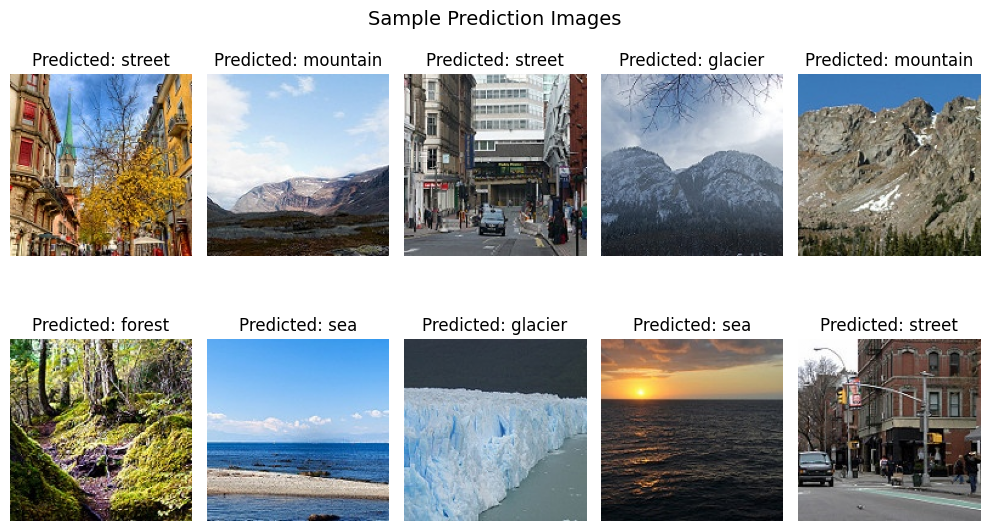

In [ ]:
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = sorted(os.listdir(root_dir))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.root_dir, img_name)
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image


pred_path = "intel-image-classification/seg_pred/seg_pred"
pred_data = CustomDataset(pred_path, transform=transformer)

batch_size = 10
pred_loader = DataLoader(pred_data, batch_size=batch_size, shuffle=False)

model.eval()

images = next(iter(pred_loader)).to(device)

with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(10, 6))
idx = 0

for i in range(2):
    for j in range(5):
        label = class_names[predicted[idx].item()]
        ax[i, j].set_title(f"Predicted: {label}")
        img = images[idx].cpu() / 2 + 0.5  # обратное преобразование из-за трансформаций. возможно, вам оно не пригодится
        npimg = np.transpose(img.numpy(), (1, 2, 0))
        ax[i, j].imshow(npimg)
        ax[i, j].axis("off")
        idx += 1

plt.tight_layout()
plt.suptitle("Sample Prediction Images", fontsize=14)
plt.show()

### RNN (6 баллов)

Recurrent Neural Network или рекуррентная нейронная сеть. Её логическим продолжением стала архитектура LSTM (Long Short-term Memory). Эти архитектуры призваны решать задачу обработки последовательностей и учитывают не только сигналы с непосредственно предыдщуего слоя, но и сигналы с более дальних слоёв.

[Здесь](https://qudata.com/ml/ru/NN_RNN_Torch.html) можно найти хорошее объяснение.

Будем решать задачу генерации текста. Принцип работы следующий: модель имеет представление обо всех словах словаря. На вход модель получает последовательность слов, её задача - определить, какое слово из словаря будет наиболее вероятным продолжением этой последовательности. То есть, по сути решается задача многоклассовой классификации.

В данном случае под "словом" понимает токен - то есть любая единица текстовых данных, которой присвоен код, - будь то буква, слог, слово или несколько слов сразу.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import re
import random
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [ ]:
# !pip install nltk==3.8.1 -q
# nltk.download('punkt', quiet=True)

В качестве данных возьмем любую из книг "Игра престолов". Тексты книг можно найти [здесь](https://www.kaggle.com/datasets/khulasasndh/game-of-thrones-books).

Начнем с небольшой предобработки. Напишите функцию предобработки, которая приведет текст к нижнему регистру, удалит из него конструкции вида "Page n". Также удалим все символы, которые не являются буквами, пробелами, точками или вопросительными знаками. В том числе удалим переносы строк.

In [ ]:
def preprocess_text(text):
    # Приведение к нижнему регистру
    text = text.lower()
    # Удаление конструкций "Page N""
    text = re.sub(r'page\s+\d+', '', text)
    # Замена переносов строк пробелом
    text = text.replace('\n', ' ').replace('\r', ' ')
    # Оставляем только буквы, пробелы, точки и вопросительные знаки
    text = re.sub(r"[^a-z .?]", '', text)
    # Убираем лишние пробелы
    text = re.sub(r' +', ' ', text).strip()
    return text

Теперь нам потребуется токенизатор, который будет присваивать словам числовые коды. В качестве метода разбиения текста на составные части предлагается использовать`sent_tokenize` и `word_tokenize` из `nltk`.

In [ ]:
class Tokenizer:
    def __init__(self):
        self.unknown_token = 'UNK'
        self.pad_token = 'PAD'

        self.unknown_index = 0
        self.pad_index = 1

        self.word2ind = {
            self.unknown_token: self.unknown_index,
            self.pad_token: self.pad_index
        }

        self.ind2word = {
            self.unknown_index: self.unknown_token,
            self.pad_index: self.pad_token
        }

    def fit(self, corpus):
        idx = 2

        for sentence in corpus:
            for word in word_tokenize(sentence):
                if word not in self.word2ind:
                    self.word2ind[word] = idx
                    self.ind2word[idx] = word
                    idx += 1

    def text2ind(self, text):
        words = word_tokenize(text)
        sequence = [self.word2ind.get(word, self.unknown_index) for word in words]
        return sequence

    def ind2text(self, sequence):
        words = [self.ind2word.get(index, self.unknown_token) for index in sequence]
        return words

Подготовим датасет. Для обучения модели было бы неплохо привести все подаваемые на вход сети последовательности к одной длине. Можно работать и с последовательностями разной длины, если объединять их в батчи, где длины совпадают, но сейчас мы будем придерживаться более простой тактики.

Реализуйте функцию `split_sentences_into_chunks`, которая будет возвращать последовательности длиной `max_seq_length + 1` (единица, так как в дальнейшем крайнее правое слово станет таргетом). Будем добавлять паддинг слева, если длина текста не делится на `max_seq_length + 1` нацело. В качестве значения для паддинга можете использовать `tokenizer.unknown_index`.

In [ ]:
def split_sentences_into_chunks(
    sentences,
    tokenizer,
    max_seq_length=8
):
    chunks = []

    pad_token = tokenizer.pad_index
    target_len = max_seq_length + 1

    for sentence in sentences:
        tokens = tokenizer.text2ind(sentence)

        if len(tokens) < target_len:
            padded = (
                [pad_token] * (target_len - len(tokens))
                + tokens
            )
            chunks.append(padded)

        else:
            for i in range(len(tokens) - max_seq_length):
                chunk = tokens[i:i + target_len]
                chunks.append(chunk)

    return chunks

Теперь создадим класс датасета. Единственная его задача - разделять входную последовательность на то, по чему мы предсказываем, и то, что мы предсказываем. На выходе должны получаться пары вида ([токены], токен).

In [ ]:
class TextDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        chunk = self.data[idx]
        X = chunk[:-1]
        y = chunk[-1]
        return torch.tensor(X), torch.tensor(y)

Сложим всё воедино:

In [ ]:
with open('/content/001ssb.txt', 'r') as file:  # файл с книгой
    text = file.read()

preprocessed_text = preprocess_text(text)

sentences = sent_tokenize(preprocessed_text)

tokenizer = Tokenizer()
tokenizer.fit(sentences)

max_seq_length = 10

data = split_sentences_into_chunks(
    sentences,
    tokenizer,
    max_seq_length=max_seq_length
)

random.shuffle(data)

split_ratio = 0.9

train_data = data[:int(split_ratio * len(data))]
test_data = data[int(split_ratio * len(data)):]

train_dataset = TextDataset(train_data)
test_dataset = TextDataset(test_data)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

Создайте нейронную сеть минимум из следующих слоев: `Embedding`, `LSTM`, `Dropout`, `Linear`.

In [ ]:
class TextGenModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=256,
        pad_index=1
    ):
        super(TextGenModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_index
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            num_layers=2
        )

        self.dropout = nn.Dropout(0.3)

        self.linear = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x):
        embedded = self.dropout(
            self.embedding(x)
        )

        lstm_out, _ = self.lstm(embedded)

        last_out = self.dropout(
            lstm_out[:, -1, :]
        )

        logits = self.linear(last_out)

        return logits

Обучите модель. Можно использовать тот же пайплайн, что и в предыдущих заданиях.

Нужно отметить, что Accuracy не очень подходит в качестве метрики для задач генерации текста, так как явялется очень грубым приближением качества. Будем ориентироваться не на значение метрики, а на динамику.

Если ваша модель при инференсе не выдает `unk` бесконечно, значит вы всё сделали правильно.

In [ ]:
def train(model, train_loader, criterion, optimizer, scheduler, device):
    model.train()
    running_loss   = 0.0
    correct_train  = 0
    total_train    = 0

    for inputs, labels in tqdm(train_loader):
        # Перемещение данных на устройство (GPU или CPU)
        inputs, labels = inputs.to(device), labels.to(device)
        # Обнуление градиентов параметров модели
        optimizer.zero_grad()
        # Прямой проход: получение прогнозов от модели
        outputs = model(inputs)
        # Вычисление значения функции потерь
        loss = criterion(outputs, labels)
        # Обратное распространение: вычисление градиентов
        loss.backward()
        # Обновление параметров модели с помощью оптимизатора
        optimizer.step()
        # Вычисление точности модели (Accuracy)
        _, predicted = torch.max(outputs, 1)
        correct_train += (predicted == labels).sum().item()
        total_train   += labels.size(0)
        # Аккумулирование потерь по батчам (взвешенно по размеру батча)
        running_loss  += loss.item() * inputs.size(0)

    # Вычисление средней потери и точности на тренировочном наборе данных
    train_loss     = running_loss / total_train
    train_accuracy = correct_train / total_train
    # Обновление шага расписания (scheduler) — после шага оптимизатора
    scheduler.step()

    return train_loss, train_accuracy


def test(model, test_loader, criterion, device):
    model.eval()
    running_loss  = 0.0
    correct_test  = 0
    total_test    = 0

    with torch.no_grad():
        # Проход по данным тестового загрузчика
        for inputs, labels in tqdm(test_loader):
            # Перемещение данных на устройство (GPU или CPU)
            inputs, labels = inputs.to(device), labels.to(device)
            # Получение прогнозов от модели
            outputs = model(inputs)
            # Вычисление значения функции потерь
            loss = criterion(outputs, labels)
            # Вычисление точности модели (Accuracy)
            _, predicted = torch.max(outputs, 1)
            correct_test += (predicted == labels).sum().item()
            total_test   += labels.size(0)
            # Аккумулирование потерь по батчам
            running_loss += loss.item() * inputs.size(0)

    # Вычисление средней потери и точности на тестовом наборе данных
    test_loss     = running_loss / total_test
    test_accuracy = correct_test / total_test

    return test_loss, test_accuracy


In [ ]:
from tqdm.auto import tqdm

In [ ]:
vocab_size = len(tokenizer.word2ind)

rnn_model = TextGenModel(
    vocab_size=vocab_size,
    embedding_dim=128,
    hidden_dim=256,
    pad_index=tokenizer.pad_index
).to(device)

rnn_criterion = nn.CrossEntropyLoss()

rnn_optimizer = optim.Adam(
    rnn_model.parameters(),
    lr=0.001
)

rnn_scheduler = lr_scheduler.StepLR(
    rnn_optimizer,
    step_size=5,
    gamma=0.5
)

num_epochs_rnn   = 15
rnn_train_losses, rnn_test_losses = [], []
rnn_train_accs,   rnn_test_accs   = [], []

for epoch in range(num_epochs_rnn):
    tr_loss, tr_acc = train(
        rnn_model, train_loader, rnn_criterion, rnn_optimizer, rnn_scheduler, device
    )
    te_loss, te_acc = test(rnn_model, test_loader, rnn_criterion, device)

    rnn_train_losses.append(tr_loss)
    rnn_test_losses.append(te_loss)
    rnn_train_accs.append(tr_acc)
    rnn_test_accs.append(te_acc)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs_rnn} | "
        f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc:.4f} | "
        f"Test Loss:  {te_loss:.4f} | Test Acc:  {te_acc:.4f}"
    )

  0%|          | 0/3480 [00:00<?, ?it/s]

  0%|          | 0/387 [00:00<?, ?it/s]

Epoch 01/15 | Train Loss: 5.6341 | Train Acc: 0.2223 | Test Loss:  5.2779 | Test Acc:  0.2396


  0%|          | 0/3480 [00:00<?, ?it/s]

  0%|          | 0/387 [00:00<?, ?it/s]

Epoch 02/15 | Train Loss: 5.1622 | Train Acc: 0.2436 | Test Loss:  5.0862 | Test Acc:  0.2576


... (35 outputs left out)

Epoch 14/15 | Train Loss: 3.7708 | Train Acc: 0.3062 | Test Loss:  5.2020 | Test Acc:  0.2854


  0%|          | 0/3480 [00:00<?, ?it/s]

  0%|          | 0/387 [00:00<?, ?it/s]

Epoch 15/15 | Train Loss: 3.7253 | Train Acc: 0.3088 | Test Loss:  5.2456 | Test Acc:  0.2862


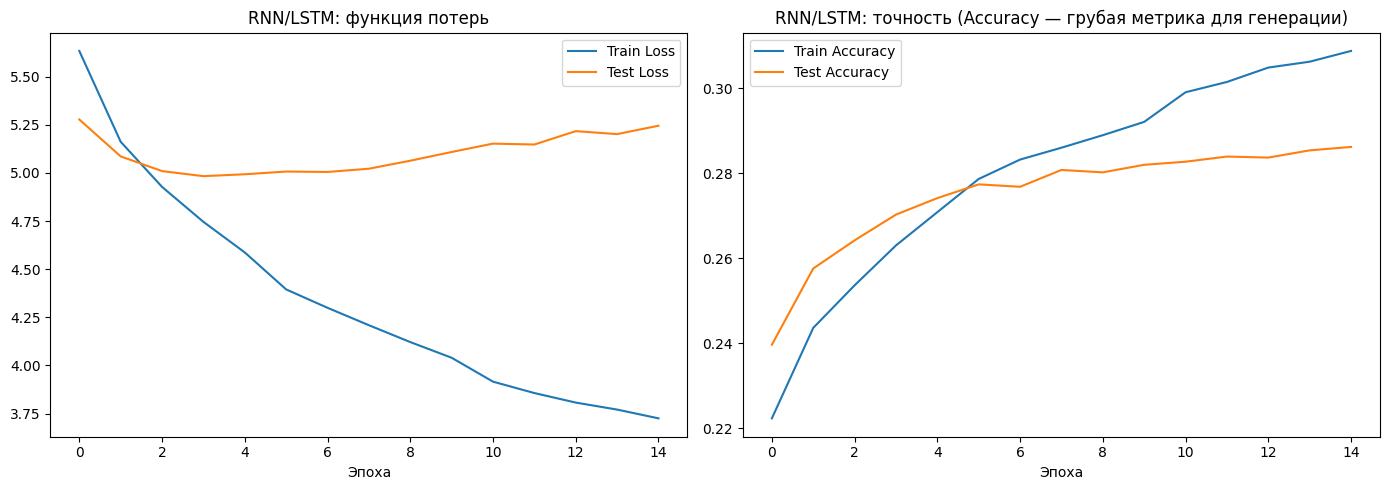

In [ ]:
# Графики
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(rnn_train_losses, label='Train Loss')
ax1.plot(rnn_test_losses,  label='Test Loss')
ax1.set_title('RNN/LSTM: функция потерь')
ax1.set_xlabel('Эпоха'); ax1.legend()

ax2.plot(rnn_train_accs, label='Train Accuracy')
ax2.plot(rnn_test_accs,  label='Test Accuracy')
ax2.set_title('RNN/LSTM: точность (Accuracy — грубая метрика для генерации)')
ax2.set_xlabel('Эпоха'); ax2.legend()

plt.tight_layout()
plt.show()

# Псевдоним: следующие ячейки с generate_text используют переменную model
model = rnn_model

Попробуйте сгенерировать вашей моделью какой-либо текст. Похоже на слог "Игры престолов"?

In [ ]:
def generate_text(seed_text, tokenizer, model, max_seq_length=8, max_len=120, device='cpu', stops=['.']):
    stops = [tokenizer.word2ind.get(stop) for stop in stops]  # если мы встретили какой-либо из данных символов, то прекращаем генерацию

    model.eval()
    with torch.no_grad():
        seed_tokens = tokenizer.text2ind(seed_text)  # токенизируем текст
        current_tokens = seed_tokens[:]

        if len(current_tokens) < max_seq_length:  # добавим паддинг, если текст слишком короткий
            current_tokens = [tokenizer.unknown_index] * (max_seq_length - len(current_tokens)) + current_tokens

        while len(current_tokens) < max_len:
            inputs = torch.tensor(current_tokens[-max_seq_length:]).unsqueeze(0).to(device)

            outputs = model(inputs)  # предсказания модели
            _, predicted = torch.max(outputs, 1)  # возьмем самый вероятный токен. можно брать случайный из какого-то топа, чтобы добавить случайность
            current_tokens.append(predicted.item())

            if current_tokens[-1] in stops:
                break

    return tokenizer.ind2text(current_tokens)  # преобразование из токенов обратно в слова. можно добавить пост-обработку

In [ ]:
print(generate_text("winter is", tokenizer, model, max_len=120, device=device))

['UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'winter', 'is', 'the', 'noise', 'of', 'the', 'seven', 'kingdoms', '.']


In [ ]:
print(generate_text("you", tokenizer, model, max_len=120, device=device))

['UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'you', '.']


In [ ]:
print(generate_text("i am", tokenizer, model, max_len=120, device=device))

['UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'i', 'am', 'you', '.']


In [ ]:
print(generate_text("when the", tokenizer, model, max_len=120, device=device))

['UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'when', 'the', 'king', 'was', 'a', 'long', 'man', '.']


In [ ]:
print(generate_text("it was a", tokenizer, model, max_len=120, device=device))

['UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'it', 'was', 'a', 'long', 'man', '.']


#### Задание 1. Улучшенная генерация текста (Temperature + Top-k sampling)

В базовой версии лабораторной работы генерация следующего слова выполняется жадным способом: модель выбирает токен с максимальной вероятностью (`argmax`).

Такой подход часто приводит к однообразному и повторяющемуся тексту.

Чтобы сделать генерацию более естественной и разнообразной, реализуйте **семплирование** следующего токена на основе распределения вероятностей.

##### Требуется:

1. Добавить поддержку **temperature sampling**:

$$
p = softmax(logits / T)
$$

Где параметр `T` управляет "уверенностью" модели:

- `T < 1` делает генерацию более детерминированной
- `T > 1` увеличивает разнообразие, но может ухудшать связность текста
2. Реализовать **top-k sampling**:

Перед выбором следующего токена оставьте только `k` наиболее вероятных слов, а остальные обнулите.

##### Эксперимент:

Сгенерируйте текст при разных параметрах:

- Temperature: `0.7`, `1.0`, `1.3`
- Top-k: `5`, `20`, `50`

Сравните результаты и сделайте вывод, как параметры влияют на качество и разнообразие текста.

In [ ]:
def generate_text_sampling(
    seed_text,
    tokenizer,
    model,
    max_seq_length=8,
    max_len=120,
    device='cpu',
    stops=['.'],
    temperature=1.0,
    top_k=20
):
    stops = [
        tokenizer.word2ind.get(stop)
        for stop in stops
    ]

    model.eval()

    with torch.no_grad():
        seed_tokens = tokenizer.text2ind(seed_text)
        current_tokens = seed_tokens[:]

        # Padding слева
        if len(current_tokens) < max_seq_length:
            current_tokens = (
                [tokenizer.unknown_index] *
                (max_seq_length - len(current_tokens))
                + current_tokens
            )

        while len(current_tokens) < max_len:

            inputs = torch.tensor(
                current_tokens[-max_seq_length:]
            ).unsqueeze(0).to(device)

            # Получаем logits модели
            outputs = model(inputs)
            logits = outputs[0]

            # Temperature sampling
            logits = logits / temperature

            # Top-k sampling
            k = min(top_k, logits.size(-1))

            top_values, top_indices = torch.topk(
                logits,
                k
            )

            # Убираем все токены, кроме top-k
            filtered_logits = torch.full_like(
                logits,
                float('-inf')
            )

            filtered_logits[top_indices] = top_values

            # Получаем вероятности
            probabilities = torch.softmax(
                filtered_logits,
                dim=-1
            )

            # Сэмплируем следующий токен
            predicted = torch.multinomial(
                probabilities,
                num_samples=1
            ).item()

            current_tokens.append(predicted)

            # Остановка на точке
            if predicted in stops:
                break

    return tokenizer.ind2text(current_tokens)

In [ ]:
print("Temperature = 0.7")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=0.7,
            top_k=20
        )
    )
)

print("\nTemperature = 1.0")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=1.0,
            top_k=20
        )
    )
)

print("\nTemperature = 1.3")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=1.3,
            top_k=20
        )
    )
)

Temperature = 0.7
UNK UNK UNK UNK UNK UNK UNK UNK winter is that the first men had left her on the kings .

Temperature = 1.0
UNK UNK UNK UNK UNK UNK UNK UNK winter is not .

Temperature = 1.3
UNK UNK UNK UNK UNK UNK UNK UNK winter is .


In [ ]:
print("Top-k = 5")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=1.0,
            top_k=5
        )
    )
)

print("\nTop-k = 20")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=1.0,
            top_k=20
        )
    )
)

print("\nTop-k = 50")
print(
    ' '.join(
        generate_text_sampling(
            "winter is",
            tokenizer,
            model,
            max_seq_length=10,
            max_len=120,
            device=device,
            temperature=1.0,
            top_k=50
        )
    )
)

Top-k = 5
UNK UNK UNK UNK UNK UNK UNK UNK winter is the noise of his sword .

Top-k = 20
UNK UNK UNK UNK UNK UNK UNK UNK winter is to be done .

Top-k = 50
UNK UNK UNK UNK UNK UNK UNK UNK winter is with blistered when he did he was afraid .


#### Задание 2. Masked Language Modeling (задача восстановления пропусков)

В качестве дополнительного задания можно реализовать альтернативный подход к обучению языковых моделей — **Masked Language Modeling**, как в архитектуре BERT.

Вместо предсказания следующего слова модель должна восстанавливать случайно замаскированные слова внутри последовательности.

Пример:
```
the king <MASK> in the north .
```
Модель должна предсказать: `is`

##### Требуется:

1. Добавить специальный токен `<MASK>`
2. В датасете случайно заменять часть слов на `<MASK>`
3. Обучить модель восстанавливать исходные слова на замаскированных позициях

In [ ]:
mlm_tokenizer = Tokenizer()

# Сначала создаём обычный словарь
mlm_tokenizer.fit(sentences)

# Только после fit добавляем MASK
mlm_tokenizer.mask_token = '<MASK>'
mlm_tokenizer.mask_index = len(mlm_tokenizer.word2ind)

mlm_tokenizer.word2ind[mlm_tokenizer.mask_token] = mlm_tokenizer.mask_index
mlm_tokenizer.ind2word[mlm_tokenizer.mask_index] = mlm_tokenizer.mask_token

print("MASK index:", mlm_tokenizer.mask_index)
print("MASK в word2ind:", mlm_tokenizer.word2ind['<MASK>'])
print("MASK в ind2word:", mlm_tokenizer.ind2word[mlm_tokenizer.mask_index])

MASK index: 11943
MASK в word2ind: 11943
MASK в ind2word: <MASK>


In [ ]:
class MLMDataset(Dataset):
    def __init__(
        self,
        sentences,
        tokenizer,
        mask_probability=0.15,
        max_seq_length=10
    ):
        self.sentences = sentences
        self.tokenizer = tokenizer
        self.mask_probability = mask_probability
        self.max_seq_length = max_seq_length

    def __len__(self):
        return len(self.sentences)


    def __getitem__(self, idx):
        sentence = self.sentences[idx]

        tokens = self.tokenizer.text2ind(sentence)
        tokens = tokens[:self.max_seq_length]

        if len(tokens) < self.max_seq_length:
            tokens = tokens + [
                self.tokenizer.unknown_index
            ] * (self.max_seq_length - len(tokens))

        original_tokens = tokens.copy()
        masked_tokens = tokens.copy()

        labels = [-1] * self.max_seq_length

        # Реальные токены, которые можно маскировать
        valid_positions = [
            i for i, token in enumerate(tokens)
            if token != self.tokenizer.unknown_index
        ]

        # Маскируем случайные слова
        for i in valid_positions:
            if random.random() < self.mask_probability:
                labels[i] = original_tokens[i]
                masked_tokens[i] = self.tokenizer.mask_index

        # Гарантируем хотя бы одну маску
        if valid_positions and all(label == -1 for label in labels):
            i = random.choice(valid_positions)
            labels[i] = original_tokens[i]
            masked_tokens[i] = self.tokenizer.mask_index

        return (
            torch.tensor(masked_tokens, dtype=torch.long),
            torch.tensor(labels, dtype=torch.long)
        )


In [ ]:
mlm_dataset = MLMDataset(
    sentences,
    mlm_tokenizer,
    mask_probability=0.15,
    max_seq_length=10
)

mlm_loader = DataLoader(
    mlm_dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
X_batch, y_batch = next(iter(mlm_loader))

for i in range(5):
    print(i)
    print("Токены:", mlm_tokenizer.ind2text(X_batch[i].tolist()))
    print("Target:", y_batch[i].tolist())
    print()

0
Токены: ['<MASK>', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK']
Target: [32, -1, -1, -1, -1, -1, -1, -1, -1, -1]

1
Токены: ['they', 'made', '<MASK>', 'songs', 'about', 'it', '.', 'UNK', 'UNK', 'UNK']
Target: [-1, -1, 408, -1, -1, -1, -1, -1, -1, -1]

2
Токены: ['<MASK>', 'ship', '?', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK']
Target: [880, -1, -1, -1, -1, -1, -1, -1, -1, -1]

3
Токены: ['<MASK>', 'many', '?', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK', 'UNK']
Target: [490, -1, -1, -1, -1, -1, -1, -1, -1, -1]

4
Токены: ['i', '<MASK>', 'refuse', '<MASK>', 'ned', 'said', 'as', 'he', 'turned', 'back']
Target: [-1, 73, -1, 84, -1, -1, -1, -1, -1, -1]



In [ ]:
class MLMModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=256,
        pad_index=0
    ):
        super(MLMModel, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_index
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            batch_first=True,
            num_layers=2
        )

        self.dropout = nn.Dropout(0.3)

        self.linear = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x):
        embedded = self.embedding(x)
        embedded = self.dropout(embedded)

        lstm_out, _ = self.lstm(embedded)
        lstm_out = self.dropout(lstm_out)

        logits = self.linear(lstm_out)

        return logits

In [ ]:
mlm_vocab_size = len(mlm_tokenizer.word2ind)

mlm_model = MLMModel(
    vocab_size=mlm_vocab_size,
    embedding_dim=128,
    hidden_dim=256,
    pad_index=mlm_tokenizer.unknown_index
).to(device)

print("Размер словаря:", mlm_vocab_size)
print(mlm_model)

Размер словаря: 11944
MLMModel(
  (embedding): Embedding(11944, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (linear): Linear(in_features=256, out_features=11944, bias=True)
)


In [ ]:
X_batch, y_batch = next(iter(mlm_loader))

X_batch = X_batch.to(device)

with torch.no_grad():
    output = mlm_model(X_batch)

print("Вход:", X_batch.shape)
print("Выход:", output.shape)

Вход: torch.Size([32, 10])
Выход: torch.Size([32, 10, 11944])


In [ ]:
mlm_criterion = nn.CrossEntropyLoss(ignore_index=-1)

print(mlm_criterion)

CrossEntropyLoss()


In [ ]:
mlm_optimizer = optim.Adam(
    mlm_model.parameters(),
    lr=0.001
)

mlm_scheduler = lr_scheduler.StepLR(
    mlm_optimizer,
    step_size=5,
    gamma=0.5
)

In [ ]:
def train_mlm(model, loader, criterion, optimizer, scheduler, device):
    model.train()

    running_loss = 0.0
    total_batches = 0

    for inputs, targets in tqdm(loader):
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        # Предсказания модели
        outputs = model(inputs)

        # [batch, seq_len, vocab_size]
        # превращаем в [batch * seq_len, vocab_size]
        outputs = outputs.reshape(-1, outputs.size(-1))

        # [batch, seq_len]
        # превращаем в [batch * seq_len]
        targets = targets.reshape(-1)

        # Loss считается только там, где target != -1
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        total_batches += 1

    scheduler.step()

    return running_loss / total_batches

In [ ]:
num_epochs_mlm = 10

mlm_losses = []

for epoch in range(num_epochs_mlm):
    loss = train_mlm(
        mlm_model,
        mlm_loader,
        mlm_criterion,
        mlm_optimizer,
        mlm_scheduler,
        device
    )

    mlm_losses.append(loss)

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs_mlm} | "
        f"MLM Loss: {loss:.4f}"
    )

  0%|          | 0/842 [00:00<?, ?it/s]

Epoch 01/10 | MLM Loss: 6.3789


  0%|          | 0/842 [00:00<?, ?it/s]

Epoch 02/10 | MLM Loss: 5.9614


  0%|          | 0/842 [00:00<?, ?it/s]

Epoch 03/10 | MLM Loss: 5.7739


... (10 outputs left out)

  0%|          | 0/842 [00:00<?, ?it/s]

Epoch 09/10 | MLM Loss: 5.3804


  0%|          | 0/842 [00:00<?, ?it/s]

Epoch 10/10 | MLM Loss: 5.3468


In [ ]:
def predict_mask(text, tokenizer, model, device, max_seq_length=10):
    model.eval()

    tokens = tokenizer.text2ind(text)

    # Сохраняем исходную длину
    original_length = min(len(tokens), max_seq_length)

    # Ищем позиции MASK
    mask_positions = [
        i for i, token in enumerate(tokens[:max_seq_length])
        if token == tokenizer.mask_index
    ]

    tokens = tokens[:max_seq_length]

    # Padding
    if len(tokens) < max_seq_length:
        tokens += [
            tokenizer.unknown_index
        ] * (max_seq_length - len(tokens))

    input_tensor = torch.tensor(
        tokens,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(input_tensor)
        predictions = torch.argmax(outputs, dim=-1)

    result = tokens[:original_length]

    for position in mask_positions:
        result[position] = predictions[0, position].item()

    return tokenizer.ind2text(result)

In [ ]:
import random

mlm_model.eval()

for _ in range(10):
    sentence = random.choice(sentences)

    tokens = mlm_tokenizer.text2ind(sentence)

    # Берём только достаточно короткие предложения
    if len(tokens) < 3 or len(tokens) > 10:
        continue

    # Выбираем реальное слово, которое можно замаскировать
    position = random.randrange(len(tokens))
    original_id = tokens[position]
    original_word = mlm_tokenizer.ind2word[original_id]

    # Создаём masked-версию
    masked_tokens = tokens.copy()
    masked_tokens[position] = mlm_tokenizer.mask_index

    input_tensor = torch.tensor(
        masked_tokens,
        dtype=torch.long
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = mlm_model(input_tensor)
        prediction_id = torch.argmax(
            outputs[0, position]
        ).item()

    prediction_word = mlm_tokenizer.ind2word[prediction_id]

    print(
        f"Оригинал: {original_word:15} "
        f"| Предсказание: {prediction_word}"
    )

Оригинал: were            | Предсказание: was
Оригинал: it              | Предсказание: you
Оригинал: scared          | Предсказание: a
Оригинал: shoulders       | Предсказание: feet


In [ ]:
text = "the king <MASK> in the north ."

result = predict_mask(
    text,
    mlm_tokenizer,
    mlm_model,
    device
)

print("Исходный текст:", text)
print("Предсказание:", result)

Исходный текст: the king <MASK> in the north .
Предсказание: ['the', 'king', 'UNK', 'UNK', 'UNK', 'in', 'the', 'north', '.']


В задании была реализована задача Masked Language Modeling: часть слов заменялась на MASK, после чего модель обучалась восстанавливать исходные слова. Loss снизился с 6.38 до 5.35, однако предсказания получались не всегда корректными, поскольку модель простая и обучалась на ограниченном количестве данных. В целом задача реализована и модель научилась восстанавливать отдельные слова, но качество генерации остаётся невысоким.


Если интересно, можно изучить и попробовать повторить [туториал про работу LLM](https://levelup.gitconnected.com/building-a-million-parameter-llm-from-scratch-using-python-f612398f06c2). Кажется, что результаты той модели должны быть лучше, нежели однослойной LSTM-ки :)

### Что еще?

Лабораторная работа получилось достаточно объемной, поэтому мы не будем рассматривать в ней перенос обучения и fine-tuning. Однако при желании вы можете изучить материалы самостоятельно. [Про разницу transfer learning-а и fine-tuning-а](https://dev.to/luxacademy/understanding-the-differences-fine-tuning-vs-transfer-learning-370).

Основная идея переноса обучения заключается в том, что кто-то уже обучил сложную и тяжелую нейронную сеть за нас, а мы теперь используем признаки, которые эта сеть умеет находить, для решения нашей задачи, надстраивая над ней небольшую "шапку", которую мы и обучаем.

Fine-tuning очень похож на перенос обучения, но помимо обучения "шапки" мы так же размораживаем для обучения часть весов модели.

[Хороший пример дообучения BERT-а для задачи анализа тональности](https://github.com/curiousily/Getting-Things-Done-with-Pytorch/blob/master/08.sentiment-analysis-with-bert.ipynb).